# Overview

Here we process output files from Sapiens2 model from json format into workable csv

In [1]:
import sys, json, csv, glob, os
import pandas as pd
import numpy
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.signal
import numpy as np

curfolder = os.getcwd()

coordfolder = os.path.join(curfolder, 'Sapiens_Output')
vidfolder = os.path.join(curfolder, 'GTST_sampled')
processedfolder = os.path.join(curfolder, 'Sapiens_Processed')

if not os.path.exists(processedfolder):
    os.makedirs(processedfolder)

vidfiles = glob.glob(os.path.join(vidfolder, '*.mp4'))
coordfiles = glob.glob(os.path.join(coordfolder, '*', '*.json'))

In [2]:
coordsample = coordfiles[0]

# Load in json file
df = pd.read_json(coordsample)
df.head() # Note that it's double-nested

,video,fps,n_frames,frames
pose_out_predictions,GP01_ADLER,50,1,"{'video': 'pose_out', 'image_size': [1080, 192..."


# Pre-Process json to csv

In [10]:
sys.path.append(os.path.join(curfolder, 'Sapiens'))
from keypoints308 import dataset_info
_ki = dataset_info["keypoint_info"]
KP_NAMES = [_ki[i]["name"] for i in range(len(_ki))]
IDX = {KP_NAMES[i]: i for i in range(len(KP_NAMES))}

CONF_THR = 0.6

import cv2

def unwrap(d):
    fps, video = d.get("fps"), d.get("video")
    node, pred = d["frames"], None
    if isinstance(node, dict):
        cands = [v for v in node.values() if isinstance(v, dict) and "frames" in v]
        if cands:
            # cases 1 & 2: prediction block present (alone or mixed with per-frame entries)
            pred = cands[0]
            video = video or pred.get("video")
            node = pred["frames"]
        else:
            # case 3: dict of per-frame entries only
            node = [v for k, v in sorted(node.items())
                    if isinstance(v, dict) and "instances" in v]
    return node, fps, video, pred

def get_image_size(pred, video, video_dir=None, default=(1080, 1920)):
    """Returns (H, W)."""
    if pred is not None and "image_size" in pred:
        return pred["image_size"]
    if video_dir is not None:
        for ext in (".mp4", ".mov", ".avi", ".MP4", ".MOV"):
            vp = os.path.join(video_dir, video + ext)
            if os.path.exists(vp):
                cap = cv2.VideoCapture(vp)
                W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
                H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
                cap.release()
                if W and H:
                    return H, W
    print(f"  warning: no image_size for {video}, using default {default}")
    return default

def person_center(inst):
    kp = np.array(inst["keypoints"], float)
    sc = np.array(inst["keypoint_scores"], float)
    good = sc >= CONF_THR
    if good.sum() == 0:
        x1, y1, x2, y2 = inst["bbox"]
        return np.array([(x1 + x2) / 2, (y1 + y2) / 2])
    return kp[good].mean(axis=0)

def person_trunk_size(inst):
    """Shoulder->hip height; falls back to shoulder width if hips aren't confident."""
    kp = np.array(inst["keypoints"], float)
    sc = np.array(inst["keypoint_scores"], float)
    good = sc >= CONF_THR
    def pt(name):
        i = IDX[name]; return kp[i] if good[i] else None
    ls, rs = pt("left_shoulder"), pt("right_shoulder")
    lh, rh = pt("left_hip"), pt("right_hip")
    if ls is not None and rs is not None and lh is not None and rh is not None:
        return np.linalg.norm((lh + rh) / 2 - (ls + rs) / 2)   # trunk height
    if ls is not None and rs is not None:
        return np.linalg.norm(ls - rs)                          # fallback: shoulder width
    return 0.0

def person_score(inst, cx, cy):
    """Lower = more central AND larger (nearer). inf if no usable trunk."""
    c = person_center(inst)
    dist = np.hypot(c[0] - cx, c[1] - cy)
    trunk = person_trunk_size(inst)
    if trunk <= 0:
        return np.inf
    return dist / trunk

def order_by_center_and_trunk(instances, cx, cy):
    return sorted(instances, key=lambda i: person_score(i, cx, cy))

def json_to_wide_csv(json_path, csv_path):
    with open(json_path) as f:
        d = json.load(f)
    frames, fps, video, pred = unwrap(d)

    H, W = get_image_size(pred, video, video_dir=vidfolder)  # videofolder = wherever the raw videos are
    cx, cy = W / 2, H / 2

    n_persons = max((len(fr["instances"]) for fr in frames), default=1)
    header = ["video", "frame", "time_s"]
    for p in range(1, n_persons + 1):
        for nm in KP_NAMES:
            header += [f"p{p}_{nm}_x", f"p{p}_{nm}_y", f"p{p}_{nm}_conf"]

    with open(csv_path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(header)
        for fr in frames:
            idx = int(os.path.splitext(fr["image_name"])[0])
            row = {"video": video, "frame": idx, "time_s": idx / fps if fps else ""}
            insts = order_by_center_and_trunk(fr["instances"], cx, cy)
            for p, inst in enumerate(insts, 1):
                for nm, (x, y), s in zip(KP_NAMES, inst["keypoints"], inst["keypoint_scores"]):
                    row[f"p{p}_{nm}_x"] = x
                    row[f"p{p}_{nm}_y"] = y
                    row[f"p{p}_{nm}_conf"] = s
            w.writerow([row.get(c, "") for c in header])
    return n_persons

json_err = []
for jp in coordfiles:
    print(jp)
    try:
        n = json_to_wide_csv(jp, jp[:-5] + ".csv")
        print(f"wrote {os.path.basename(jp)[:-5]}.csv  ({n} person(s))")
    except Exception as e:
        print('error', e)
        json_err.append((jp, e))

g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ADLER\GP01_ADLER_pose.json
wrote GP01_ADLER_pose.csv  (1 person(s))
g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ANSTECKEN\GP01_ANSTECKEN_pose.json
wrote GP01_ANSTECKEN_pose.csv  (1 person(s))
g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ARBEITEN\GP01_ARBEITEN_pose.json
wrote GP01_ARBEITEN_pose.csv  (1 person(s))
g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ARGUMENTIEREN\GP01_ARGUMENTIEREN_pose.json
wrote GP01_ARGUMENTIEREN_pose.csv  (1 person(s))
g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BLITZ\GP01_BLITZ_pose.json
wrote GP01_BLITZ_pose.csv  (1 person(s))
g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BODEN\GP01_BODEN_pose.json
wrote GP01_BODEN_pose.csv  (1 person(s))
g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BRIEF\GP01_BRIEF_pose.json
wrote GP01_BRIEF_pose.csv  (1 person(s))
g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BUERO\GP01_BUERO_pose.json
wrote GP01_BUERO_pose.csv  (1 person(s))
g:\GtST_FLESH_KinTrajectory

In [11]:
json_err


[]

<Axes: xlabel='frame'>

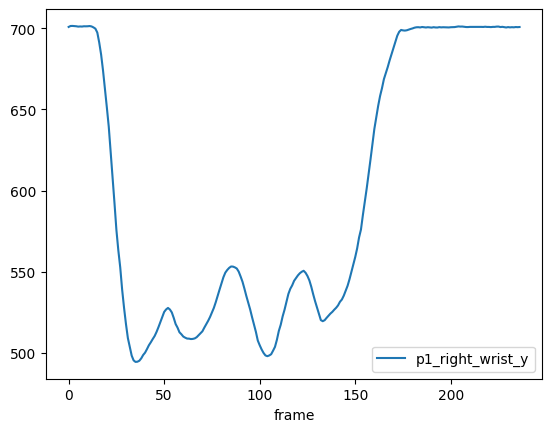

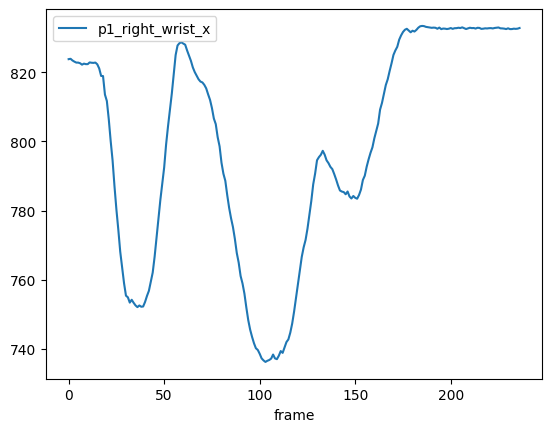

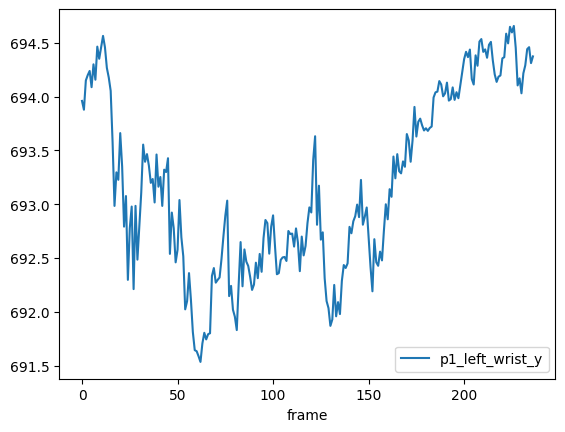

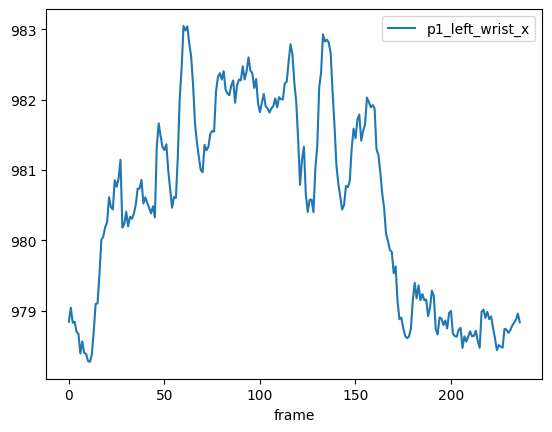

In [12]:
csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*GP01_ANSTECKEN_pose.csv'))
sample_df = pd.read_csv(csvfiles[0])

# plot wrist
sample_df.plot(x='frame', y='p1_right_wrist_y') # should move once up and once down - notice it's FLIPPED
sample_df.plot(x='frame', y='p1_right_wrist_x') # should slightly move left and right
sample_df.plot(x='frame', y='p1_left_wrist_y') # should not move
sample_df.plot(x='frame', y='p1_left_wrist_x') # should not move

## Check people association (in multi-party frames)

In [ ]:
sys.path.append(os.path.join(curfolder, 'Sapiens'))
from keypoints308 import dataset_info

csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*_pose.csv'))
csvfiles = [f for f in csvfiles if not os.path.basename(f).startswith('LP')] # exclude LP trials

_ki = dataset_info["keypoint_info"]
KP_NAMES = [_ki[i]["name"] for i in range(len(_ki))]
_name2id = {n: i for i, n in enumerate(KP_NAMES)}
SKELETON_EDGES = [(_name2id[a], _name2id[b])
                  for s in dataset_info["skeleton_info"].values()
                  for a, b in [s["link"]]
                  if a in _name2id and b in _name2id]

def person_xy(row, p):
    """Return (308x2 array, 308 conf) for person p from a dataframe row; NaN where missing."""
    xs = np.array([row.get(f"p{p}_{n}_x", np.nan) for n in KP_NAMES], float)
    ys = np.array([row.get(f"p{p}_{n}_y", np.nan) for n in KP_NAMES], float)
    cs = np.array([row.get(f"p{p}_{n}_conf", np.nan) for n in KP_NAMES], float)
    return np.column_stack([xs, ys]), cs

def draw(img, kpts, conf, color, thr=0.3):
    for a, b in SKELETON_EDGES:
        if conf[a] < thr or conf[b] < thr: continue
        if np.isnan(kpts[[a, b]]).any(): continue
        cv2.line(img, tuple(kpts[a].astype(int)), tuple(kpts[b].astype(int)), color, 2)
    for i in range(len(kpts)):
        if conf[i] < thr or np.isnan(kpts[i]).any(): continue
        cv2.circle(img, tuple(kpts[i].astype(int)), 4, color, -1)

for file in csvfiles:
    df = pd.read_csv(file)
    if not any(df.columns.str.contains('p2_')):
        continue
    print('found p2 in', file)

    # frames where BOTH persons have any keypoints -> pick the richest one
    p1_valid = df.filter(regex=r'^p1_.*_conf$').notna().sum(axis=1)
    p2_valid = df.filter(regex=r'^p2_.*_conf$').notna().sum(axis=1)
    both = df[(p1_valid > 0) & (p2_valid > 0)]
    if both.empty:
        print('  no frame has both -> p2 is sporadic; probably safe'); continue
    ridx = (p1_valid + p2_valid).loc[both.index].idxmax()   # most complete frame
    row = df.loc[ridx]
    frame_vis = int(row['frame'])
    print('  showing frame', frame_vis)

    name = os.path.basename(file).split('_pose.csv')[0]
    videofile = glob.glob(os.path.join(curfolder, 'GTST_sampled', name + '*.mp4'))[0]

    cap = cv2.VideoCapture(videofile)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_vis)
    ok, img = cap.read()
    cap.release()
    if not ok:
        print('  could not read frame'); continue

    k1, c1 = person_xy(row, 1)
    k2, c2 = person_xy(row, 2)
    draw(img, k1, c1, (0, 255, 0))     # p1 = green
    draw(img, k2, c2, (0, 0, 255))     # p2 = red

    plt.figure(figsize=(10, 7))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{name}  frame {frame_vis}   p1=green  p2=red")
    plt.axis('off'); plt.show()

Now we can see that in only multi-party cases, p1 is the person of interest. We can therefore proceed with keeping only p1_* in the data

# Confidence check

Sapiens2 outputs confidence for each keypoint for each frame. We can create summarization for each keypoint (and participant) to see whether there are some major hick-ups that would favor exclusion of data

In [3]:
csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*_pose.csv'))
csvfiles = [f for f in csvfiles if not os.path.basename(f).startswith('LP')] # exclude LP trials


In [ ]:

TOCHECK = ['nose', 'shoulder', 'elbow', 'hip', 'thumb', 'finger', 'wrist', 'neck']
conf_list = []

for csvfile in csvfiles:
    df = pd.read_csv(csvfile)
    fileID = os.path.basename(csvfile).split('_')[0]
    # keep only columns that contain string from TOCHECK and 'conf'
    df = df[[col for col in df.columns if any([x in col for x in TOCHECK]) and 'conf' in col and 'p1_' in col and '_of_' not in col]]
    for c in df.columns:
        conf_list.append([fileID, c, df[c].mean(), df[c].std()])

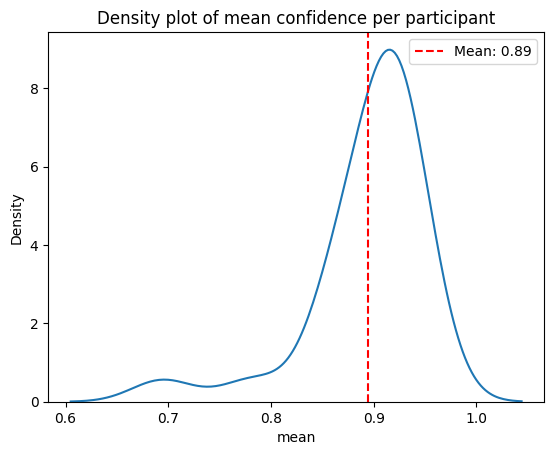

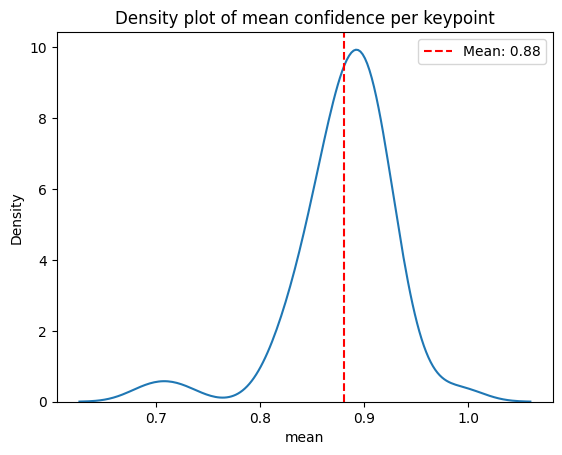

In [14]:
# Calculate mean confidence per participant (fileID)
conf_df = pd.DataFrame(conf_list, columns=['fileID', 'column', 'mean', 'std'])
conf_pcn_mean = conf_df.groupby('fileID')['mean'].mean().reset_index()
conf_kpt_mean = conf_df.groupby('column')['mean'].mean().reset_index()

# Density plot of mean confidence (pcn)
sns.kdeplot(data=conf_pcn_mean, x='mean')
plt.title('Density plot of mean confidence per participant')
plt.axvline(conf_pcn_mean['mean'].mean(), color='red', linestyle='--', label=f'Mean: {conf_pcn_mean["mean"].mean():.2f}')
plt.legend()
plt.show()

# Density plot of mean confidence (keypoint)
sns.kdeplot(data=conf_kpt_mean, x='mean')
plt.title('Density plot of mean confidence per keypoint')
plt.axvline(conf_kpt_mean['mean'].mean(), color='red', linestyle='--', label=f'Mean: {conf_kpt_mean["mean"].mean():.2f}')
plt.legend()
plt.show()


In [15]:
# Which participants have mean below 0.7
conf_pcn_mean[conf_pcn_mean['mean'] < 0.7]

,fileID,mean
18,IP10,0.694652


# Further processing (sample)

## Cleaning

In [4]:
csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*_pose.csv'))
csvsample = csvfiles[0]

TOKEEP = ['nose', 'shoulder', 'elbow', 'hip', 'thumb', 'finger', 'wrist', 'neck']

def flip_axis(df):
    cols = [col for col in df.columns if '_y' in col]
    
    # Identify the maximum value in the first row of the Y_
    maxpoint = max(df.loc[0, cols])

    # Flip all Y_ columns across all rows
    for joint in cols:
        df.loc[:, joint] = maxpoint - df[joint] - 1
            
    return df

def interpolate(df):
    cols = df.columns
    cols = cols.drop(['time_s', 'frame', 'FileID'])

    # loop over the cols and interpolate missing data
    for col in cols:
        df[col] = df[col].interpolate(method='linear', x = df['time_s'], limit=10)
    return df


def clean_and_process_df(file, colstokeep):
    df = pd.read_csv(file)
    name = os.path.basename(file).split('_pose.csv')[0]

    # Get frame and time_s columns
    frames = df['frame']
    time_s = df['time_s']

    # Keep only p1_ columns
    df = df.loc[:, df.columns.str.contains('p1_')]
    
    # Keep only columns that share strings with elements in colstokeep
    df = df.loc[:, df.columns.str.contains('|'.join(colstokeep))]

    # Rename columns to remove p1_ prefix
    df.columns = df.columns.str.replace('p1_', '')

    # Get rid of columns that have '_of_' in (residuals of nose columns that we don't need)
    df = df.loc[:, ~df.columns.str.contains('_of_')]

    # Flip y axis
    df = flip_axis(df)

    # Add name as FileID
    df['FileID'] = name

    # Add time and frames in the beginning
    df['frame'] = frames
    df['time_s'] = time_s

    # Interpolate
    df = interpolate(df)

    return df

sample_proc = clean_and_process_df(csvsample, TOKEEP)
sample_proc.head()

# Plot wrist in y
plt.plot(sample_proc['time_s'], sample_proc['right_wrist_y'])

IndexError: list index out of range

## Smoothing 

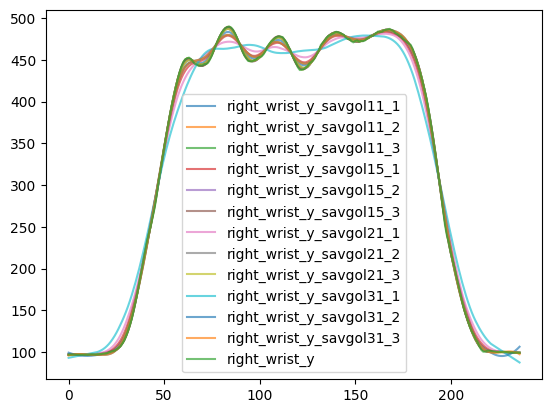

In [ ]:
# test the different smoothing filter options - smoothing with savitzky-golay filter
x = 'right_wrist_y'
y = 'right_wrist_x'


# list possible window
window = [11, 15, 21, 31]
# list possible orders
order = [1, 2, 3]

# col of interest
samplecol = [y, x]

df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample_proc[col], win, ord)


# make a copy of col
col_x = sample_proc[x].tolist()
col_y = sample_proc[y].tolist()

df_smooth[x] = col_x
df_smooth[y] = col_y

colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
plt.show()

In [ ]:
sys.path.append(os.path.join(curfolder, 'Sapiens'))
from keypoints308 import dataset_info

_ki = dataset_info["keypoint_info"]
KP_NAMES = [_ki[i]["name"] for i in range(len(_ki))]
_name2id = {n: i for i, n in enumerate(KP_NAMES)}
SKELETON_EDGES = [(_name2id[a], _name2id[b], s["color"])
                  for s in dataset_info["skeleton_info"].values()
                  for a, b in [s["link"]]
                  if a in _name2id and b in _name2id]

CONF_THR = 0.3
COMBOS = [(11, 2), (15,2), (21, 2)]      # <-- your three (window, order) choices

def smooth_series(vals, conf, win, order):
    """Mask low-conf -> interpolate -> savgol. vals, conf are 1D arrays over frames."""
    s = pd.Series(vals, dtype=float)
    s[conf < CONF_THR] = np.nan
    s = s.interpolate(limit_direction="both")     # fill gaps so savgol can run
    if s.isna().all():
        return vals                                # nothing usable; leave as-is
    if len(s) <= win:
        return s.to_numpy()                        # too short to filter
    return scipy.signal.savgol_filter(s.to_numpy(), win, order)

def build_smoothed(df, person, win, order):
    """Return dict name -> (x_arr, y_arr) smoothed across all frames for one person."""
    out = {}
    for nm in KP_NAMES:
        cx = df.get(f"{person}_{nm}_x")
        cy = df.get(f"{person}_{nm}_y")
        cc = df.get(f"{person}_{nm}_conf")
        if cx is None:
            continue
        conf = cc.to_numpy() if cc is not None else np.ones(len(df))
        out[nm] = (smooth_series(cx.to_numpy(), conf, win, order),
                   smooth_series(cy.to_numpy(), conf, win, order))
    return out

def draw_skeleton(img, coords_by_name, fi, color=None):
    """Draw skeleton and keypoints on an image frame using smoothed coordinates.

    Args:
        img: Input image frame to draw on
        coords_by_name: Dictionary mapping keypoint names to (x,y) coordinate arrays
        fi: Frame index to use for drawing
        color: Optional override color for skeleton and keypoints (BGR format)
    """
    def pt(nm):
        if nm not in coords_by_name: return None
        x, y = coords_by_name[nm][0][fi], coords_by_name[nm][1][fi]
        return None if (np.isnan(x) or np.isnan(y)) else (int(x), int(y))
    for a, b, c in SKELETON_EDGES:
        pa, pb = pt(KP_NAMES[a]), pt(KP_NAMES[b])
        if pa and pb:
            cv2.line(img, pa, pb, (color or c[::-1]), 2)
    for nm in coords_by_name:
        p = pt(nm)
        if p: cv2.circle(img, p, 3, (color or (0, 255, 0)), -1)
    return img

def render_smoothing_qc(csv_path, video_path, out_dir, person="p1"):
    """Generate QC videos showing skeleton smoothing with different Savitzky-Golay filter parameters.

    Args:
        csv_path: Path to CSV file containing pose estimation data
        video_path: Path to original video file
        out_dir: Directory to save output videos
        person: Person identifier in the pose data (default: "p1")

    Creates one output video per (window, order) combination showing the smoothed skeleton.
    """
    os.makedirs(out_dir, exist_ok=True)
    df = pd.read_csv(csv_path).sort_values("frame").reset_index(drop=True)
    name = os.path.basename(csv_path).split("_pose.csv")[0]

    # precompute smoothed coords for each combo
    smoothed = {combo: build_smoothed(df, person, *combo) for combo in COMBOS}

    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # one output video per combo
    writers = {combo: cv2.VideoWriter(
                   os.path.join(out_dir, f"{name}_savgol_w{combo[0]}_o{combo[1]}.mp4"),
                   cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
               for combo in COMBOS}

    for fi in range(len(df)):
        vframe = int(df.loc[fi, "frame"])
        cap.set(cv2.CAP_PROP_POS_FRAMES, vframe)
        ok, base = cap.read()
        if not ok: continue
        for combo in COMBOS:
            img = base.copy()
            draw_skeleton(img, smoothed[combo], fi, color=(0, 255, 0))
            cv2.putText(img, f"savgol win={combo[0]} order={combo[1]}", (12, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
            writers[combo].write(img)

    cap.release()
    for w in writers.values(): w.release()
    print("wrote", len(COMBOS), "videos to", out_dir)

# run on one file
filename = sample_proc['FileID'].iloc[0]
csv_path = os.path.join(curfolder, 'Sapiens_Output', filename, filename + '_pose.csv')
video_path = glob.glob(os.path.join(curfolder, "GTST_sampled", filename + "*.mp4"))[0]
render_smoothing_qc(csv_path, video_path, os.path.join(curfolder, "Smoothing_check"))

wrote 3 videos to g:\GtST_FLESH_KinTrajectory\Smoothing_check


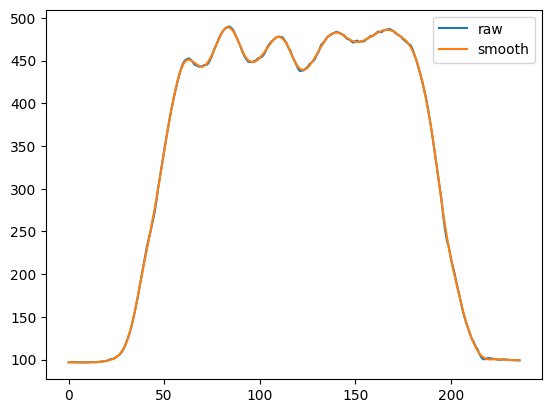

In [ ]:
def savgol_smooth(df, window=21, order=2):
    """Apply Savitzky-Golay smoothing to specified columns in a DataFrame.

    Args:
        df: Input DataFrame containing columns to smooth
        window: Window size for the Savitzky-Golay filter (must be odd)
        order: Polynomial order for the Savitzky-Golay filter

    Returns:
        DataFrame with smoothed columns (columns ending with '_x' or '_y')
    """
    df_smoothed = df.copy()
    colstosmooth = [c for c in df_smoothed.columns if c.endswith('_x') or c.endswith('_y')]
    for col in colstosmooth:
            df_smoothed[col] = scipy.signal.savgol_filter(df[col], window, order)

    return df_smoothed

sample_smooth = savgol_smooth(sample_proc, window=15, order=2)

# plot wrist_y from sample_proc and sample_smooth
plt.plot(sample_proc['right_wrist_y'], label = 'raw')
plt.plot(sample_smooth['right_wrist_y'], label = 'smooth')
plt.legend()
plt.show()

## Normalization

Given the nature of the data, we need to perform three normalization steps

- center all body-keypoint coordinates on mid-torso
- normalize all body-keypoint coordinates by average torso length per participant (to account for varying bodies)
- center all finger-keypoint coordinates on wrist
- normalize all finger-keypoint coordinates by average palm length

In [ ]:
def add_midtorso_and_center(
    df,
    l_shoulder_prefix="left_shoulder",
    r_shoulder_prefix="right_shoulder",
    l_hip_prefix="left_hip",
    r_hip_prefix="right_hip"):
    """
    Create mid-torso from shoulders and hips and center all XYZ keypoints on it.

    Returns a new DataFrame with:
      - X_midTorso, Y_midTorso, Z_midTorso added
      - All X_*, Y_*, Z_* centered on mid-torso
      - visibility_* and time unchanged
    """

    df = df.copy()

    # --- 1. Compute midpoints ---
    df["midtorso_x"] = 0.5 * (df[f"{l_shoulder_prefix}_x"] + df[f"{r_shoulder_prefix}_x"])
    df["midtorso_y"] = 0.5 * (df[f"{l_shoulder_prefix}_y"] + df[f"{r_shoulder_prefix}_y"])

    hips_mid_x = 0.5 * (df[f"{l_hip_prefix}_x"] + df[f"{r_hip_prefix}_x"])
    hips_mid_y = 0.5 * (df[f"{l_hip_prefix}_y"] + df[f"{r_hip_prefix}_y"])

    df["midtorso_x"] = 0.5 * (df["midtorso_x"] + hips_mid_x)
    df["midtorso_y"] = 0.5 * (df["midtorso_y"] + hips_mid_y)

    # --- 2. Center all XYZ columns on mid-torso ---
    x_cols = [c for c in df.columns if c.endswith("_x")]
    y_cols = [c for c in df.columns if c.endswith("_y")]

    # Get rid of columns with finger or thumb in
    x_cols = [c for c in x_cols if "finger" not in c and "thumb" not in c]
    y_cols = [c for c in y_cols if "finger" not in c and "thumb" not in c]

    for c in x_cols:
        df[c] = df[c] - df["midtorso_x"]
    for c in y_cols:
        df[c] = df[c] - df["midtorso_y"]

    return df

def center_fingers_on_wrist(df):
    """
    Center finger and thumb keypoints on their respective wrists.

    Returns a new DataFrame with:
      - Finger and thumb keypoints centered on wrists
      - All other columns unchanged
    """

    out = df.copy()
    cols = [c for c in df.columns if "finger" in c or "thumb" in c]

    right_cols = [c for c in cols if c.startswith("right_")]
    left_cols = [c for c in cols if c.startswith("left_")]

    # Get rid of conf columns and wrist
    right_cols = [c for c in right_cols if "conf" not in c]
    left_cols = [c for c in left_cols if "conf" not in c]

    # Center all on wrist
    for c in right_cols:
        axis = c.split('_')[-1]
        out[c] = df[c] - df[f"right_wrist_{axis}"]

    for c in left_cols:
        axis = c.split('_')[-1]
        out[c] = df[c] - df[f"left_wrist_{axis}"]

    return out

    
# usage on sample
sample_norm = center_fingers_on_wrist(sample_smooth)
sample_norm = add_midtorso_and_center(sample_norm)

# check that mid-torso is now at (0,0,0)
print(sample_norm[["midtorso_x", "midtorso_y"]].head())


   midtorso_x  midtorso_y
0         0.0         0.0
1         0.0         0.0
2         0.0         0.0
3         0.0         0.0
4         0.0         0.0


No trunk length provided, computing from data...
Trunk length used for normalization: 281.24383076971685
Palm length used for normalization: 30.872707564566955


C:\Users\kadava\AppData\Local\Temp\ipykernel_25556\3036267517.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["midshoulder_x"] = 0.5 * (df["left_shoulder_x"] + df["right_shoulder_x"])
C:\Users\kadava\AppData\Local\Temp\ipykernel_25556\3036267517.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["midshoulder_y"] = 0.5 * (df["left_shoulder_y"] + df["right_shoulder_y"])
C:\Users\kadava\AppData\Local\Temp\ipykernel_25556\3036267517.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result o

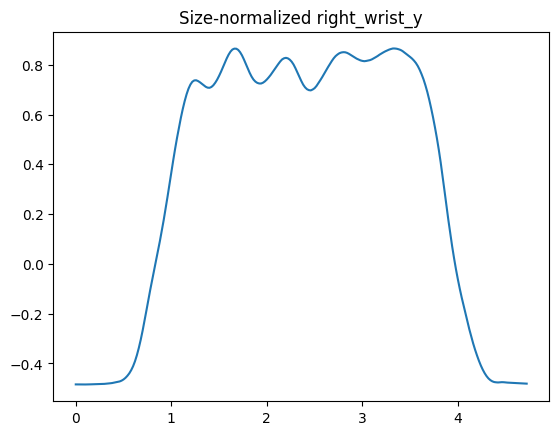

In [ ]:
def size_normalize_by_trunk(df, trunk_len=None):
    """Normalize body keypoints by trunk length (distance between mid-shoulder and mid-hip).
    If trunk_len is not provided, it is computed from the data.
    Returns the trunk length used and the normalized dataframe."""

    if trunk_len is None:

        print("No trunk length provided, computing from data...")
    
        # create mid shoulder
        df["midshoulder_x"] = 0.5 * (df["left_shoulder_x"] + df["right_shoulder_x"])
        df["midshoulder_y"] = 0.5 * (df["left_shoulder_y"] + df["right_shoulder_y"])

        # create midhip
        df["midhip_x"] = 0.5 * (df["left_hip_x"] + df["right_hip_x"])
        df["midhip_y"] = 0.5 * (df["left_hip_y"] + df["right_hip_y"])

        # compute trunk length as median distance between mid-shoulder and mid-hip
        dx = df["midshoulder_x"] - df["midhip_x"]
        dy = df["midshoulder_y"] - df["midhip_y"]

        trunk_len = np.median(np.sqrt(dx**2 + dy**2))

    else:
        print(f"Using provided trunk length: {trunk_len}") 

    xy_cols = [c for c in df.columns if c.endswith(("_x", "_y"))]
    xy_cols = [c for c in xy_cols if 'thumb' not in c and 'finger' not in c]
    for c in xy_cols:
        df[c] = df[c] / trunk_len

    return trunk_len, df

def size_normalize_by_palm(df, palm_len=None):
    """Normalize hand keypoints by palm length (distance between forefinger and pinky).
    If palm_len is not provided, it is computed from the data.
    Returns the palm length used and the normalized dataframe."""

    if palm_len is None:

        scale_left = np.sqrt(
            (df["left_forefinger_third_joint_x"] - df["left_pinky_finger_third_joint_x"])**2 +
            (df["left_forefinger_third_joint_y"] - df["left_pinky_finger_third_joint_y"])**2
        )

        scale_right = np.sqrt(
            (df["right_forefinger_third_joint_x"] - df["right_pinky_finger_third_joint_x"])**2 +
            (df["right_forefinger_third_joint_y"] - df["right_pinky_finger_third_joint_y"])**2
        )

        scale = np.median(np.concatenate([scale_left, scale_right]))
    
    else:
        print(f"Using provided palm length: {palm_len}")
        scale = palm_len

    fingcols = [c for c in df.columns if (('finger' in c) or ('thumb' in c)) and ('conf' not in c)]
    for c in fingcols:
        df[c] = df[c] / scale

    return scale, df

trunk_len, sample_norm = size_normalize_by_trunk(sample_norm)
print(f"Trunk length used for normalization: {trunk_len}")

palm_len, sample_norm = size_normalize_by_palm(sample_norm)
print(f"Palm length used for normalization: {palm_len}")

plt.plot(sample_norm['time_s'], sample_norm['right_wrist_y'])
plt.title('Size-normalized right_wrist_y')
plt.show()



In [ ]:
if not os.path.exists(os.path.join(curfolder, 'Datasets', 'median_body_length_per_pcn.csv')):
    print("median_body_length_per_pcn.csv not found, creating it...")

    error_list = []
    body_len_list = []

    # create txt file
    f = open("error_log.txt", "w")

    #for loop to go through every file in the timeseries folder
    for file in csvfiles:
        print("This is file" + str(file) + "// Count: " + str(csvfiles.index(file)) + " of " + str(len(csvfiles)) + " files in total")

        try:
            # Cleaning
            sample = clean_and_process_df(file, TOKEEP)

            try:
                fileID = sample['FileID'][0]
                #print(fileID)
            except:
                print('FileID not found')
                f.write(f'{fileID} FileID not found\n')
                continue

            sample = savgol_smooth(sample, window=15, order=2)

            # Add mid-torso and center data on it
            sample = add_midtorso_and_center(sample)
            
            # Size-normalize by trunk length
            trunk_len, sample = size_normalize_by_trunk(sample)
            palm_len, sample = size_normalize_by_palm(sample)

            # append trunk_len with fileID to trunk_len_list
            body_len_list.append((fileID, trunk_len, palm_len))
            
        except Exception as e:
            print(f"Error processing {file}: {e}")
            error_list.append(file)
            f.write(f'{file} {e}\n')
            continue
        
    f.close()

    body_len_df = pd.DataFrame(body_len_list, columns=['fileID', 'trunk_len', 'palm_len'])

    # create a median trunk and palm length per pcn_ID
    body_len_df['pcn_ID'] = body_len_df['fileID'].apply(lambda x: x.split('_')[0])
    median_trunk_len_df = body_len_df.groupby('pcn_ID')['trunk_len'].median().reset_index()
    median_palm_len_df = body_len_df.groupby('pcn_ID')['palm_len'].median().reset_index()
    median_body_len_df = pd.merge(median_trunk_len_df, median_palm_len_df, on='pcn_ID')


    median_body_len_df.to_csv(os.path.join(curfolder, 'median_body_length_per_pcn.csv'), index=False)
    median_body_len_df.head(10)

else:
    print("median_body_length_per_pcn.csv already exists, loading it...")
    median_body_len_df = pd.read_csv(os.path.join(curfolder, 'Datasets', 'median_body_length_per_pcn.csv'))

median_body_length_per_pcn.csv not found, creating it...
This is fileg:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ADLER\GP01_ADLER_pose.csv// Count: 0 of 1561 files in total
No trunk length provided, computing from data...
This is fileg:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ANSTECKEN\GP01_ANSTECKEN_pose.csv// Count: 1 of 1561 files in total
No trunk length provided, computing from data...
This is fileg:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ARBEITEN\GP01_ARBEITEN_pose.csv// Count: 2 of 1561 files in total
No trunk length provided, computing from data...
This is fileg:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ARGUMENTIEREN\GP01_ARGUMENTIEREN_pose.csv// Count: 3 of 1561 files in total
No trunk length provided, computing from data...
This is fileg:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BLITZ\GP01_BLITZ_pose.csv// Count: 4 of 1561 files in total
No trunk length provided, computing from data...
This is fileg:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BODEN\GP

In [ ]:
median_body_len_df.head(10)

,pcn_ID,trunk_len,palm_len
0,GP01,269.998946,39.257405
1,GP02,285.492156,35.452768
2,GP03,276.370186,33.124610
3,GP04,254.166562,34.097173
4,GP05,242.721067,35.145263
5,GP06,241.819806,24.233098
6,GP08,232.415292,33.303183
7,GP10,267.003218,28.165475
8,GP11,261.962389,35.775822
9,GP14,267.435231,22.191178


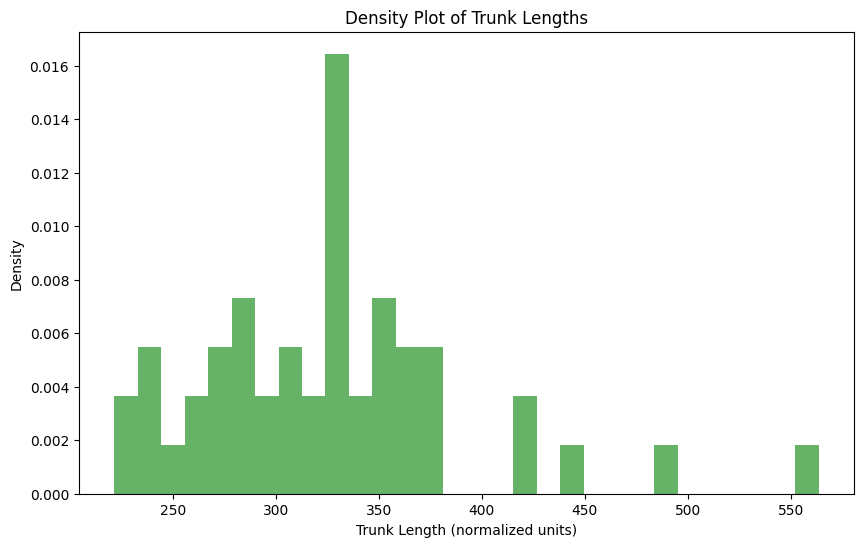

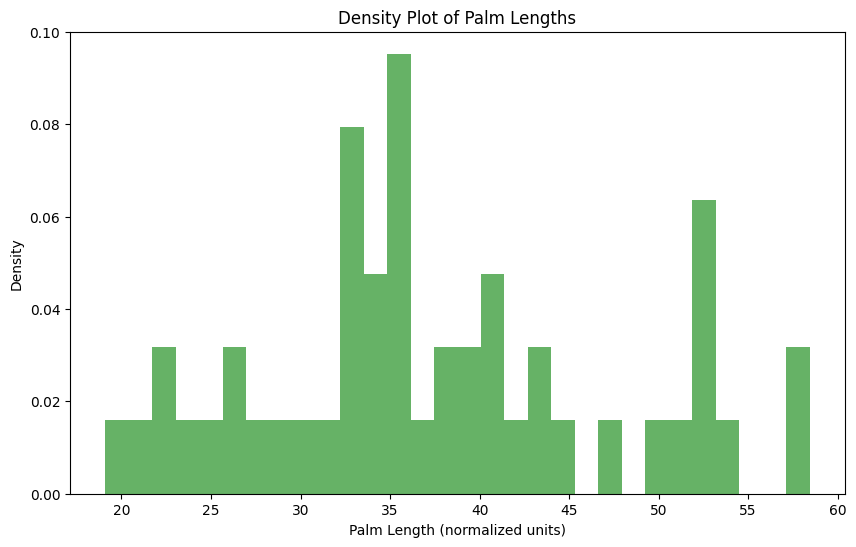

In [ ]:
# density plot for trunk
plt.figure(figsize=(10, 6))
plt.hist(median_body_len_df['trunk_len'], bins=30, density=True, alpha=0.6, color='g')
plt.title('Density Plot of Trunk Lengths')
plt.xlabel('Trunk Length (normalized units)')
plt.ylabel('Density')
plt.show()

# density plot for palm
plt.figure(figsize=(10, 6))
plt.hist(median_body_len_df['palm_len'], bins=30, density=True, alpha=0.6, color='g')
plt.title('Density Plot of Palm Lengths')
plt.xlabel('Palm Length (normalized units)')
plt.ylabel('Density')
plt.show()

## Deriving 

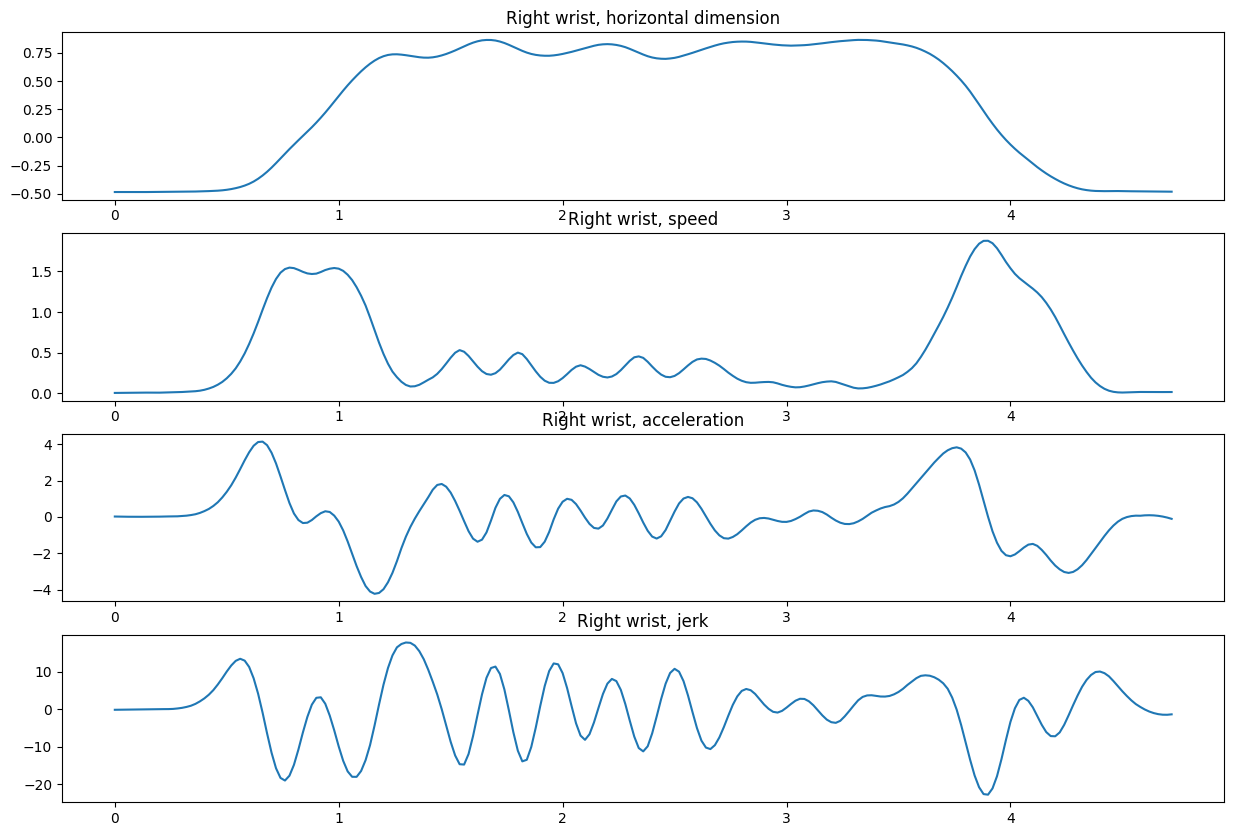

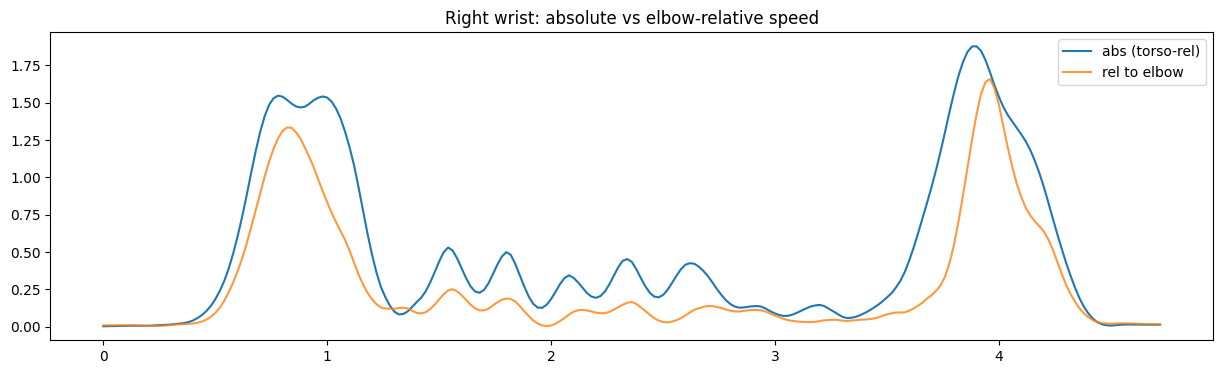

In [ ]:
PARENT_MAP = {
    "right_wrist": "right_elbow",  "right_elbow": "right_shoulder",
    "left_wrist":  "left_elbow",   "left_elbow":  "left_shoulder",
}

def _smooth(sig, win=15, poly=2):
    win = min(win, len(sig) - (1 - len(sig) % 2))      
    return scipy.signal.savgol_filter(sig, win, poly) if win > poly else sig

def process_derivs(df, sr):
    """Processes a DataFrame containing keypoint coordinates to compute speed, acceleration, and jerk.

    Args:
        df (pd.DataFrame): DataFrame containing keypoint coordinates with columns in format 'keypoint_x' and 'keypoint_y'.
        sr (float): Sampling rate of the data in Hz.

    Returns:
        pd.DataFrame: The input DataFrame with additional columns for speed, acceleration, and jerk metrics.
    """
    df = df.reset_index(drop=True)

    bases = sorted({c[:-2] for c in df.columns if c.endswith(("_x", "_y"))})

    speed_dict = {}
    for b in bases:
        if f"{b}_x" not in df.columns or f"{b}_y" not in df.columns:
            continue
        x, y = df[f"{b}_x"].to_numpy(), df[f"{b}_y"].to_numpy()

        # absolute speed (torso-relative for gross kpts, palm-relative for fingers,
        # by virtue of the centering you've already applied)
        speed = np.insert(np.sqrt(np.diff(x)**2 + np.diff(y)**2), 0, 0) * sr
        speed_dict[f"{b}_speed"] = _smooth(speed)

        # parent-relative speed: VECTOR diff first, THEN magnitude
        parent = PARENT_MAP.get(b)
        if parent and f"{parent}_x" in df.columns:
            px, py = df[f"{parent}_x"].to_numpy(), df[f"{parent}_y"].to_numpy()
            rdx = np.diff(x) - np.diff(px)          # <-- the fix: subtract as vectors
            rdy = np.diff(y) - np.diff(py)
            relspeed = np.insert(np.sqrt(rdx**2 + rdy**2), 0, 0) * sr
            speed_dict[f"{b}_relspeed"] = _smooth(relspeed)

    df = pd.concat([df, pd.DataFrame(speed_dict, index=df.index)], axis=1)

    # acceleration = d/dt of every speed/relspeed column (subtract ONCE, then only differentiate)
    accel = {}
    for col in [c for c in df.columns if c.endswith("speed")]:
        a = np.insert(np.diff(df[col].to_numpy()), 0, 0) * sr
        accel[col.replace("speed", "acc")] = _smooth(a)
    df = pd.concat([df, pd.DataFrame(accel, index=df.index)], axis=1)

    # jerk = d/dt of every acc/relacc column
    jerk = {}
    for col in [c for c in df.columns if c.endswith("acc")]:
        j = np.insert(np.diff(df[col].to_numpy()), 0, 0) * sr
        jerk[col.replace("acc", "jerk")] = _smooth(j)
    df = pd.concat([df, pd.DataFrame(jerk, index=df.index)], axis=1)

    return df


sr = round(len(sample_norm) / (sample_norm['time_s'].iloc[-1] - sample_norm['time_s'].iloc[0]), 0)
sample_der = process_derivs(sample_norm, sr=30.0)

# Plot
plt.figure(figsize=(15, 10))
plt.subplot(4, 1, 1)
plt.plot(sample_der['time_s'], sample_der['right_wrist_y'])
plt.title('Right wrist, horizontal dimension')
plt.subplot(4, 1, 2)
plt.plot(sample_der['time_s'], sample_der['right_wrist_speed'])
plt.title('Right wrist, speed')
plt.subplot(4,1,3)
plt.plot(sample_der['time_s'], sample_der['right_wrist_acc'])
plt.title('Right wrist, acceleration')
plt.subplot(4,1,4)
plt.plot(sample_der['time_s'], sample_der['right_wrist_jerk'])
plt.title('Right wrist, jerk')    
plt.show()

# compare absolute (torso-relative) vs parent-relative wrist speed
plt.figure(figsize=(15, 4))
plt.plot(sample_der['time_s'], sample_der['right_wrist_speed'],    label='abs (torso-rel)')
plt.plot(sample_der['time_s'], sample_der['right_wrist_relspeed'], label='rel to elbow', alpha=0.8)
plt.legend(); plt.title('Right wrist: absolute vs elbow-relative speed'); plt.show()

In [ ]:
sample_der.head()

,nose_x,nose_y,nose_conf,left_shoulder_x,left_shoulder_y,left_shoulder_conf,right_shoulder_x,right_shoulder_y,right_shoulder_conf,left_elbow_x,...,right_ring_finger3_jerk,right_ring_finger4_jerk,right_ring_finger_third_joint_jerk,right_shoulder_jerk,right_thumb2_jerk,right_thumb3_jerk,right_thumb4_jerk,right_thumb_third_joint_jerk,right_wrist_jerk,right_wrist_reljerk
0,-0.094696,0.842837,0.995890,0.363269,0.477875,0.906768,-0.363384,0.473822,0.894053,0.516706,...,-0.965909,-0.584110,-1.595093,-0.040025,-0.077723,0.463037,1.596969,-1.119497,-0.114203,-0.276349
1,-0.093718,0.842258,0.994249,0.363583,0.477481,0.906669,-0.363164,0.474047,0.894525,0.516572,...,-0.084790,-0.376847,-0.907829,-0.058130,-0.371694,0.025813,1.542714,-1.321038,-0.095362,-0.249734
2,-0.092756,0.841843,0.993359,0.363874,0.477137,0.905404,-0.362962,0.474254,0.893699,0.516469,...,0.630408,-0.205163,-0.279505,-0.071071,-0.574807,-0.305706,1.471255,-1.437946,-0.076323,-0.219412
3,-0.091812,0.841593,0.992332,0.364143,0.476844,0.906424,-0.362777,0.474444,0.895529,0.516397,...,1.179684,-0.069059,0.289879,-0.078850,-0.687064,-0.531519,1.382591,-1.470221,-0.057085,-0.185381
4,-0.090886,0.841507,0.991208,0.364388,0.476601,0.906283,-0.362609,0.474618,0.895539,0.516356,...,1.563040,0.031465,0.800322,-0.081466,-0.708464,-0.651627,1.276723,-1.417861,-0.037649,-0.147644


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
 
 
def resample_to_fps(df, target_fps=30, time_col='time_s',
                    coord_suffixes=('_x', '_y', '_z')):
    """Resample all coordinate columns onto an exact uniform target_fps grid.
 
    Always resamples, also when the file is already ~target_fps: this removes
    timestamp jitter (variable frame rate) and puts every file on the same grid,
    so smoothing windows and derivatives mean the same thing everywhere.
 
    The grid is built as t0 + k / target_fps (no float accumulation), so
    np.diff(time) is exactly 1/target_fps.
 
    Returns (df_out, native_fps). native_fps is the average rate of the input,
    reported for logging only.
    """
    fid = df['FileID'].iloc[0] if 'FileID' in df.columns else None
 
    # sort by time and drop duplicate timestamps (np.interp needs increasing x)
    df = df.sort_values(time_col).drop_duplicates(subset=time_col, keep='first')
    t_old = df[time_col].to_numpy(float)
    if len(t_old) < 2 or t_old[-1] <= t_old[0]:
        raise ValueError(f"{fid}: fewer than 2 distinct timestamps")
 
    dur = t_old[-1] - t_old[0]
    native_fps = (len(t_old) - 1) / dur          # N samples = N-1 intervals
 
    n_new = int(np.floor(dur * target_fps + 1e-6)) + 1
    t_new = t_old[0] + np.arange(n_new) / target_fps
 
    coord_cols = [c for c in df.columns if c.endswith(coord_suffixes)]
    out = {time_col: t_new, 'frame': np.arange(n_new)}
    for c in coord_cols:
        y = df[c].to_numpy(float)
        m = ~np.isnan(y)
        out[c] = (np.interp(t_new, t_old[m], y[m]) if m.sum() >= 2
                  else np.full(n_new, np.nan))
 
    out_df = pd.DataFrame(out)
    if fid is not None:
        out_df['FileID'] = fid
    return out_df, native_fps

# Full loop body+hand

In [44]:
warnings.filterwarnings('ignore')
 
TOKEEP = ['nose', 'shoulder', 'elbow', 'hip', 'thumb', 'finger', 'wrist', 'neck']
TARGET_FPS = 30
SG_WINDOW, SG_ORDER = 15, 2          # 15 frames = 0.5 s at 30 fps
 
errors, too_short, fps_log = [], [], []
 
median_bodylen = pd.read_csv(os.path.join(curfolder, 'Datasets', 'median_body_length_per_pcn.csv'))
 
for csv in csvfiles:
    print('Processing: ', csv)
 
    if os.path.basename(csv).startswith('LP'):
        continue
 
    try:
        df = clean_and_process_df(csv, TOKEEP)          # clean (flip + interpolate)
        df = df.loc[:, ~df.columns.str.contains('_conf')]
        df, native_fps = resample_to_fps(df, target_fps=TARGET_FPS)
    except Exception as e:
        print('Error in processing: ', csv, '->', e)
        errors.append(csv)
        continue
 
    fid = df['FileID'].iloc[0]
    fps_log.append({'FileID': fid, 'native_fps': native_fps, 'n_frames': len(df)})
 
    if len(df) < SG_WINDOW:                              # can't smooth: skip, don't mix grids
        print(f"  ! {fid}: only {len(df)} frames at {TARGET_FPS} fps (< {SG_WINDOW}); skipped")
        too_short.append(fid)
        continue
 
    df = savgol_smooth(df, window=SG_WINDOW, order=SG_ORDER)   # smooth
    df = add_midtorso_and_center(df)                            # center
    df = center_fingers_on_wrist(df)
 
    pcn_ID = fid.split('_')[0]
    row = median_bodylen[median_bodylen['pcn_ID'] == pcn_ID]
    trunklen, df = size_normalize_by_trunk(df, trunk_len=row['trunk_len'].iloc[0])   # normalize
    palmlen,  df = size_normalize_by_palm(df,  palm_len=row['palm_len'].iloc[0])
 
    # every file is on the exact grid now, so the sampling rate is known
    sr = TARGET_FPS
    assert np.allclose(np.diff(df['time_s'].to_numpy()), 1 / sr), f"{fid}: grid not uniform"
    df = process_derivs(df, sr=sr)                              # derivatives
 
    # Aggregates (parent-relative arm chain)
    df['arm_total_speed'] = np.sqrt(
        df['left_shoulder_speed']**2  + df['right_shoulder_speed']**2 +
        df['left_elbow_relspeed']**2  + df['right_elbow_relspeed']**2 +
        df['left_wrist_relspeed']**2  + df['right_wrist_relspeed']**2)
 
    df['arm_total_acc'] = np.sqrt(
        df['left_shoulder_acc']**2  + df['right_shoulder_acc']**2 +
        df['left_elbow_relacc']**2  + df['right_elbow_relacc']**2 +
        df['left_wrist_relacc']**2  + df['right_wrist_relacc']**2)
 
    df['arm_total_jerk'] = np.sqrt(
        df['left_shoulder_jerk']**2  + df['right_shoulder_jerk']**2 +
        df['left_elbow_reljerk']**2  + df['right_elbow_reljerk']**2 +
        df['left_wrist_reljerk']**2  + df['right_wrist_reljerk']**2)
 
    name = fid + '_kinematics.csv'
    df.to_csv(os.path.join(curfolder, 'Sapiens_Processed', name), index=False)
 
fps_log = pd.DataFrame(fps_log)
fps_log.to_csv(os.path.join(curfolder, 'Sapiens_Processed', '_native_fps_log.csv'), index=False)
print(f"\nDone. {len(fps_log) - len(too_short)} files written at {TARGET_FPS} fps; "
      f"{len(too_short)} too short; {len(errors)} errors.")
print(fps_log['native_fps'].describe())

Processing:  g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ADLER\GP01_ADLER_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Processing:  g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ANSTECKEN\GP01_ANSTECKEN_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Processing:  g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ARBEITEN\GP01_ARBEITEN_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Processing:  g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ARGUMENTIEREN\GP01_ARGUMENTIEREN_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Processing:  g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BLITZ\GP01_BLITZ_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Processing:  g:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BODE

# Finger distances

In [45]:
import re

# finger classification 
def canonical_finger(name):
    n = name.lower()
    if "thumb" in n:                 return "thumb"
    if "fore" in n or "index" in n:  return "index"
    if "middle" in n:                return "middle"
    if "ring" in n:                  return "ring"
    if "pink" in n or "little" in n: return "pinky"
    return None

# build finger numbers (a la MediaPipe) 
def build_handmap(df, side="right", verbose=True):
    FINGER_BASE = {"index": 5, "middle": 9, "ring": 13, "pinky": 17}
    CAT_OFFSET  = {"third_joint": 0, "2": 1, "3": 2, "4": 3}   # MCP,PIP,DIP,TIP
    THUMB_NUM   = {"third_joint": 1, "2": 2, "3": 3, "4": 4}   # CMC,MCP,IP,TIP 
    handmap = {}

    # wrist (number 0) 
    for cand in [f"{side}_wrist", f"{side}_hand_root", f"{side}_hand"]:
        if f"{cand}_x" in df.columns:
            handmap[0] = cand[len(side) + 1:]
            break

    for c in df.columns:
        if not (c.startswith(f"{side}_") and c.endswith("_x")):
            continue
        stem = c[len(side) + 1:-2]                 # e.g. "ring_finger4"
        fng  = canonical_finger(stem)
        m    = re.search(r"(third_joint|\d+)$", stem)
        if fng is None or m is None:
            continue
        cat = m.group(1)
        if fng == "thumb" and cat in THUMB_NUM:
            handmap[THUMB_NUM[cat]] = stem
        elif fng in FINGER_BASE and cat in CAT_OFFSET:
            handmap[FINGER_BASE[fng] + CAT_OFFSET[cat]] = stem

    if verbose:
        missing = set(range(21)) - set(handmap)
        for n in sorted(handmap):
            print(f"{n:2d} -> {side}_{handmap[n]}")
        if missing:
            print(f"⚠️ missing keypoint numbers: {sorted(missing)} "
                  f"-- distances using these will fail; check naming.")
    return handmap

# 2D inter-joint distance, both hands 
def gethandjointdistance(sample, handmap, j1, j2):
    out = []
    for side in ["left", "right"]:
        def coords(j):
            if j == 0:                       # wrist = finger-frame origin
                z = np.zeros(len(sample))
                return z, z
            b = handmap[j]
            return (sample[f"{side}_{b}_x"].to_numpy(),
                    sample[f"{side}_{b}_y"].to_numpy())
        x1, y1 = coords(j1); x2, y2 = coords(j2)
        dx, dy = x1 - x2, y1 - y2
        out += [dx, dy, np.sqrt(dx**2 + dy**2)]
    return out

# speed / accel / jerk on the scalar magnitude columns
def derive_speed_accel_jerk(df, sr):
    def smooth(sig):
        try:    return scipy.signal.savgol_filter(sig, 15, 3)
        except ValueError: return scipy.signal.savgol_filter(sig, 7, 3)
    for col in df.columns.drop(["time_s", "FileID"]):
        if col.endswith(("_x", "_y")):
            continue
        sp = np.abs(np.insert(np.diff(df[col]), 0, 0))
        sp = smooth(sp) * sr                # per-second
        df[col + "_speed"] = sp
        ac = smooth(np.insert(np.diff(sp), 0, 0)) * sr
        df[col + "_acc"] = ac      
        df[col + "_jerk"] = smooth(np.insert(np.diff(ac), 0, 0)) * sr
    return df

outputfolder = os.path.join(curfolder, 'Sapiens_Processed')

DISTANCE_PAIRS = [
    (4,2),(4,1),(3,1),(4,17),(2,0),(3,0),(4,0),        # thumb
    (8,6),(7,5),(8,5),(6,0),(7,0),(8,0),               # index
    (12,10),(11,9),(12,9),(10,0),(11,0),(12,0),        # middle
    (16,14),(15,13),(16,13),(14,0),(15,0),(16,0),      # ring
    (20,18),(19,17),(20,17),(18,0),(19,0),(20,0),      # pinky
    (4,8),(8,12),(12,16),(16,20),                      # adjacent fingertip spans
]

hand_distances_error = []
processed_files = glob.glob(os.path.join(outputfolder, "*kinematics*.csv"))

for file in processed_files:
    print("working on", file)
    fname = os.path.basename(file)

    if fname.startswith('LP'):
        continue
    
    df = pd.read_csv(file)
    try:
        fileID = df["FileID"][0]
    except KeyError:
        hand_distances_error.append(("missing FileID column", file)); continue

    sr = round(len(df) / (df['time_s'].iloc[-1] - df['time_s'].iloc[0]), 0) # calculate sample rate

    df = df.drop([c for c in df.columns
                  if any(k in c for k in ("speed","velocity","acc","jerk"))], axis=1)

    handmap = build_handmap(df, side="right", verbose=False)   # stems shared across sides

    try:
        records = {"FileID": fileID, "time_s": df["time_s"]}
        for j1, j2 in DISTANCE_PAIRS:
            dx_l, dy_l, d_l, dx_r, dy_r, d_r = gethandjointdistance(df, handmap, j1, j2)
            for pref, dx, dy, d in [("l", dx_l, dy_l, d_l), ("r", dx_r, dy_r, d_r)]:
                k = f"{pref}{j1}_{j2}"
                records[f"{k}_x"], records[f"{k}_y"], records[k] = dx, dy, d
        df_distances = pd.DataFrame(records)
    except KeyError as e:
        print(f"⚠️ Distances error {fileID}: {e}")
        hand_distances_error.append(("error in calculating distances", file)); continue

    try:
        df_distances = derive_speed_accel_jerk(df_distances, sr)
    except Exception as e:
        print(f"⚠️ Speed/accel/jerk error {fileID}: {e}")
        hand_distances_error.append(("error in speed/accel/jerk", file)); continue

    out_path = os.path.join(outputfolder, fname.replace("kinematics", "hand_distances"))
    df_distances.to_csv(out_path, index=False)

working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_ADLER_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_ANSTECKEN_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_ARBEITEN_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_ARGUMENTIEREN_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_BLITZ_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_BODEN_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_BRIEF_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_BUERO_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_DRECK_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_ENTSCHULDIGEN_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_GEIGE_kinematics.csv
working on g:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_GI

# Visualize

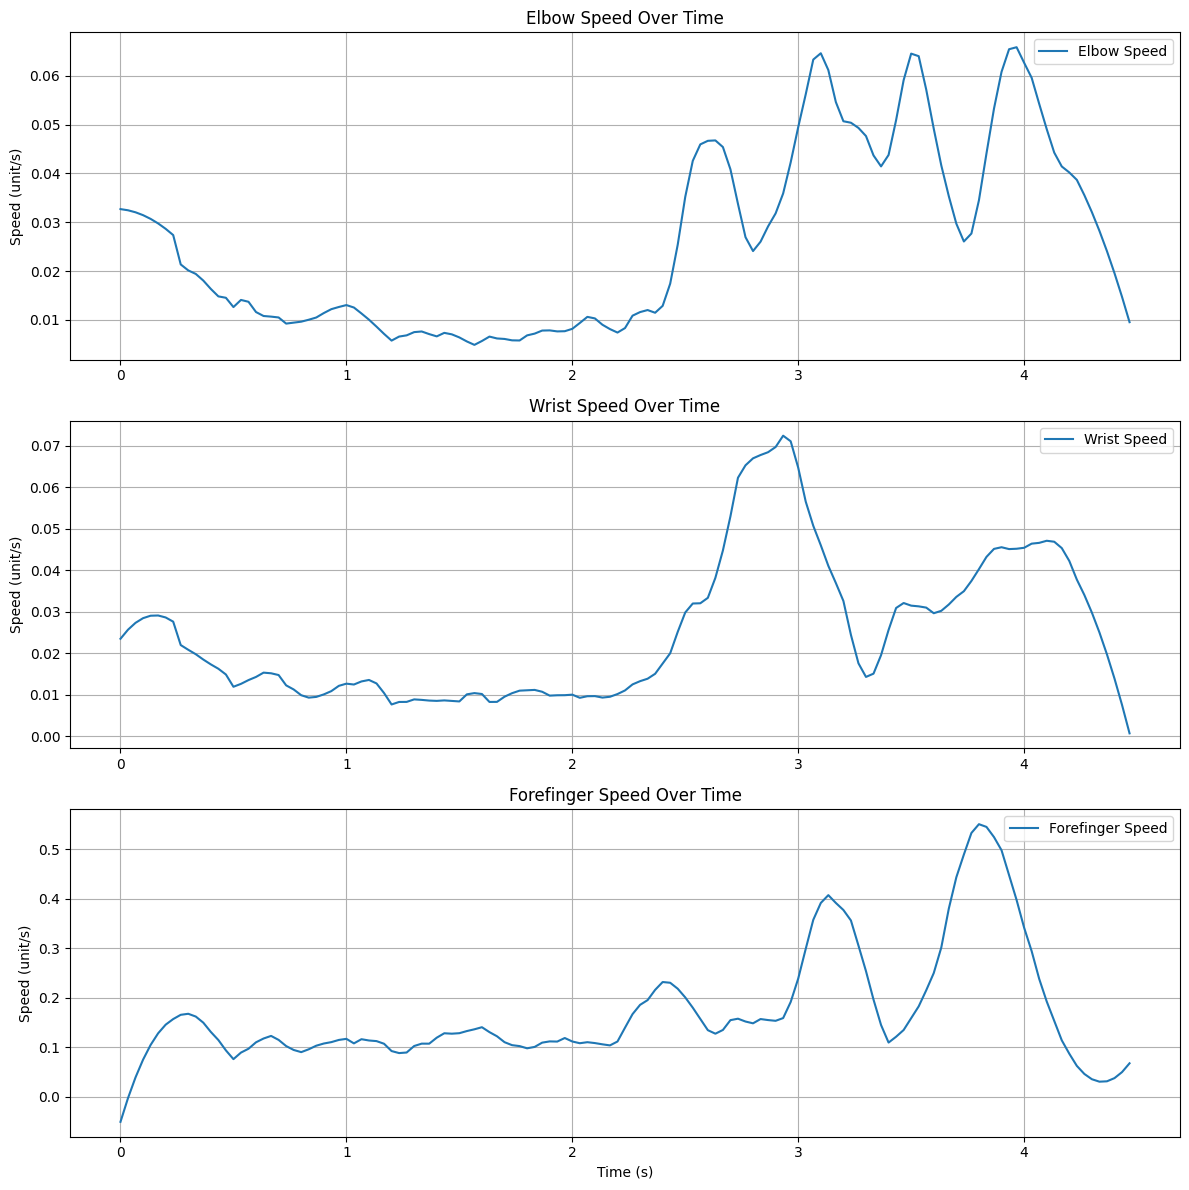

In [38]:
processedfiles = glob.glob(os.path.join(outputfolder, "*kinematics*.csv"))
sample = processedfiles[30]

data = pd.read_csv(sample)

fig, axs = plt.subplots(3, 1, figsize=(12, 12))
axs[0].plot(data['time_s'], data['right_elbow_relspeed'], label='Elbow Speed')
axs[0].set_ylabel('Speed (unit/s)')
axs[0].set_title('Elbow Speed Over Time')
axs[0].legend()
axs[0].grid(True)

axs[1].plot(data['time_s'], data['right_wrist_relspeed'], label='Wrist Speed')
axs[1].set_ylabel('Speed (unit/s)')
axs[1].set_title('Wrist Speed Over Time')
axs[1].legend()
axs[1].grid(True)

axs[2].plot(data['time_s'], data['right_forefinger4_speed'], label='Forefinger Speed')
axs[2].set_xlabel('Time (s)')
axs[2].set_ylabel('Speed (unit/s)')
axs[2].set_title('Forefinger Speed Over Time')
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()

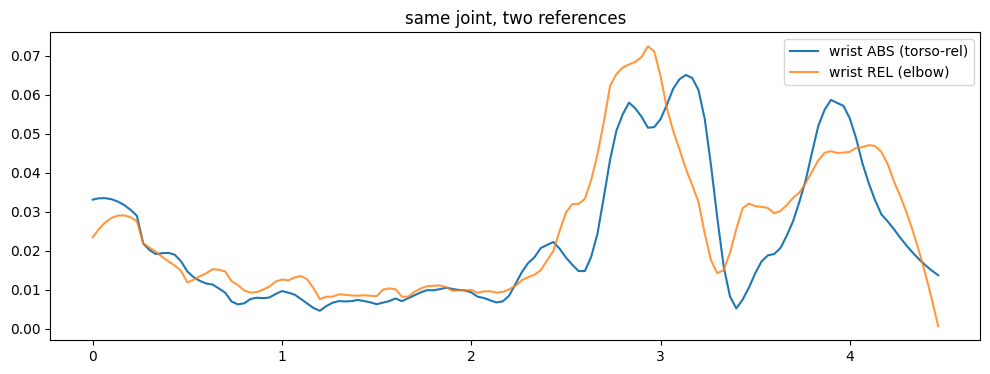

In [39]:
data.FileID

plt.figure(figsize=(12,4))
plt.plot(data.time_s, data.right_wrist_speed,    label='wrist ABS (torso-rel)')
plt.plot(data.time_s, data.right_wrist_relspeed, label='wrist REL (elbow)', alpha=.8)
plt.legend(); plt.title('same joint, two references'); plt.show()


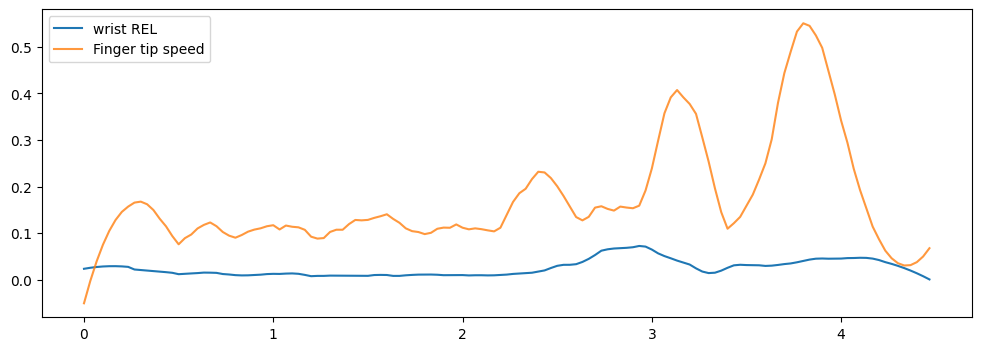

In [40]:
data.FileID

plt.figure(figsize=(12,4))
plt.plot(data.time_s, data.right_wrist_relspeed,    label='wrist REL')
plt.plot(data.time_s, data.right_forefinger4_speed, label='Finger tip speed', alpha=.8)
plt.legend(); plt.title(''); plt.show()
